# Bài toán 2 — Tank Battle: Kết quả thực nghiệm

Notebook chạy trực tiếp **mã nguồn hiện tại** trong `task2/` và bộ kiểm thử trong
`tests/`, không định nghĩa lại hay sửa thuật toán, luật game hoặc giao diện.
Bốn cấu hình: **Minimax**, **Alpha-Beta**, **Heuristic Minimax** và
**Heuristic Minimax + Alpha-Beta**.

**Nội dung:** môi trường và mã nguồn; kiểm thử; benchmark cùng trạng thái;
đối đầu đổi bên; bảng/biểu đồ; đối chiếu CSV tham khảo.
Các cell đã được thực thi và lưu output để phục vụ nộp bài.

## 1. Cách chạy lại

Giữ notebook cùng thư mục với `tanks.py`, `task2/`, `tests/`, `levels_ai/`
và `experiments/`. Mở bằng VS Code/Jupyter, chọn kernel Python 3 rồi chọn
**Restart Kernel → Run All → Save**. Không xóa output trước khi nộp.

Nếu máy chưa có công cụ notebook, cài trong terminal của môi trường Python đã chọn:

```bash
python -m pip install -r requirements.txt
python -m pip install jupyterlab ipykernel pandas matplotlib
```

Các thư viện bổ sung chỉ phục vụ notebook/bảng/biểu đồ; `requirements.txt`
của game được giữ nguyên. Notebook không mở cửa sổ game: xem UI bằng
`python tanks.py`. Phần chạy 60 trận có thể mất vài phút tùy máy.
Kết quả mới lưu ngay trong output notebook, không ghi đè CSV trong `experiments/`.

In [1]:
from pathlib import Path
import sys
import platform
import subprocess
import hashlib
import random
import json
from collections import Counter
from datetime import datetime, timezone
from importlib.metadata import version
from time import perf_counter

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")

# Tìm thư mục dự án khi kernel khởi động ở gốc hoặc một thư mục con.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "task2/game.py").is_file()
             and (p / "tests/test_core.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Hãy mở notebook từ thư mục dự án chứa task2/ và tests/.")
for path in (ROOT, ROOT / "task2"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
sys.dont_write_bytecode = True

from benchmark import (build_scenarios, measure_one, validate_pairs,
                       summarize as summarize_benchmark, MODES_ORDER)
from search import MODES
from tournament import Tournament

pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 6)

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

SOURCE_FILES = sorted(set(ROOT.glob("*.py"))
                      | set((ROOT / "task2").glob("*.py"))
                      | set((ROOT / "tests").glob("*.py")))
REFERENCE_FILES = sorted(p for p in (ROOT / "experiments").iterdir()
                         if p.suffix in (".csv", ".json"))
source_hashes_before = {str(p.relative_to(ROOT)): sha256(p) for p in SOURCE_FILES}
reference_hashes_before = {str(p.relative_to(ROOT)): sha256(p) for p in REFERENCE_FILES}
try:
    commit = subprocess.run(["git", "rev-parse", "HEAD"], cwd=ROOT,
                            capture_output=True, text=True)
    source_commit = commit.stdout.strip() if commit.returncode == 0 else "Không có metadata Git"
except FileNotFoundError:
    source_commit = "Git chưa được cài; xem SHA-256 mã nguồn ở cuối notebook"
measured_at = datetime.now(timezone.utc).isoformat()
environment = {
    "Thời điểm chạy (UTC)": measured_at,
    "Commit nguồn lúc chạy": source_commit,
    "Python": platform.python_version(),
    "Hệ điều hành": platform.system(),
    "Kiến trúc": platform.machine(),
    "pandas": version("pandas"),
    "matplotlib": version("matplotlib"),
}
display(pd.DataFrame(environment.items(), columns=["Thông tin", "Giá trị"]))
print("Đã import trực tiếp benchmark.py, search.py và tournament.py của dự án.")

,Thông tin,Giá trị
0,Thời điểm chạy (UTC),2026-11-15T11:51:42.980193+00:00
1,Commit nguồn lúc chạy,717de6be5d4aba76fe009a81d2038cf659ca96e5
2,Python,3.12.14
3,Hệ điều hành,Linux
4,Kiến trúc,x86_64
5,pandas,2.2.3
6,matplotlib,3.10.8


Đã import trực tiếp benchmark.py, search.py và tournament.py của dự án.


## 2. Cấu hình và kịch bản

- Bản thuần dùng `TerminalEvaluator`: utility tại terminal, 0 tại lá chưa terminal.
- Hai bản heuristic dùng cùng `HeuristicEvaluator`.
- Độ sâu tính bằng **ply**: một hành động của một bên.
- Benchmark không deadline, không TT, tắt PV; `measure_one` tự tạo engine/evaluator mới.
- Năm kịch bản đo giữ nguyên từ `build_scenarios`; các map chuyển khác chỉ được dùng
  trong bộ kiểm thử và game, không tự thêm vào tập đo này.

In [2]:
mode_rows = [{"mode": mode, "Thuật toán": MODES[mode][0].__name__,
              "Evaluator": MODES[mode][1].__name__} for mode in MODES_ORDER]
assert len(mode_rows) == 4
MODE_LABELS = {"minimax": "MM", "alphabeta": "AB",
               "heuristic_minimax": "H-MM", "heuristic_alphabeta": "H-AB"}
SCENARIOS = ["default", "open", "walls", "defense", "bullet"]
DEPTHS = [2, 4]
PLAYERS = [0, 1]
REPEATS = 3
SEED = 42
MATCH_DEPTH = 3
MATCH_MAX_CYCLES = 60

all_cases = build_scenarios()
cases = {name: all_cases[name] for name in SCENARIOS}
display(pd.DataFrame(mode_rows))
display(pd.DataFrame([
    {"Kịch bản": name, "Lưới": f"{state.rows} x {state.cols}",
     "Gạch": len(state.walls), "Thép": len(state.steel),
     "Đạn ban đầu": len(state.bullets),
     "Tank P0 (r,c,d,hp)": tuple(state.tanks[0]),
     "Tank P1 (r,c,d,hp)": tuple(state.tanks[1])}
    for name, state in cases.items()
]))
print(f"Có {len(all_cases)} map trong bộ dựng kịch bản; benchmark chọn {len(cases)} kịch bản.")

,mode,Thuật toán,Evaluator
0,minimax,Minimax,TerminalEvaluator
1,alphabeta,AlphaBeta,TerminalEvaluator
2,heuristic_minimax,Minimax,HeuristicEvaluator
3,heuristic_alphabeta,AlphaBeta,HeuristicEvaluator


,Kịch bản,Lưới,Gạch,Thép,Đạn ban đầu,"Tank P0 (r,c,d,hp)","Tank P1 (r,c,d,hp)"
0,default,11 x 11,24,4,0,"(10, 5, 0, 6)","(0, 5, 1, 6)"
1,open,9 x 9,0,0,0,"(7, 4, 0, 6)","(1, 4, 1, 6)"
2,walls,9 x 9,9,2,0,"(7, 4, 0, 6)","(1, 4, 1, 6)"
3,defense,9 x 9,0,0,0,"(7, 4, 0, 6)","(6, 6, 1, 6)"
4,bullet,9 x 9,0,0,1,"(7, 4, 0, 6)","(1, 4, 1, 6)"


Có 40 map trong bộ dựng kịch bản; benchmark chọn 5 kịch bản.


## 3. Kiểm thử mã nguồn hiện tại

Chạy đúng lệnh `python -m unittest discover -s tests -v` trong tiến trình riêng.
Bộ kiểm thử có oracle vét cạn độc lập đối chiếu MM/AB trên các map, hai bên,
hai evaluator ở depth 3; kiểm tra thêm luật, cận, PV, cache và giới hạn môi trường.
Không thay đổi bộ kiểm thử để làm cho kết quả đạt.

In [3]:
test_run = subprocess.run(
    [sys.executable, "-m", "unittest", "discover", "-s", "tests", "-v"],
    cwd=ROOT, capture_output=True, text=True,
)
print(test_run.stdout, end="")
print(test_run.stderr, end="")
assert test_run.returncode == 0, "Bộ kiểm thử chưa đạt; xem output phía trên."
print("PASS: Bộ kiểm thử hiện tại chạy thành công.")

open: P0 minimax / P1 alphabeta: unfinished, experiment_cycle_limit, 1 cycles
open: P0 alphabeta / P1 minimax: unfinished, experiment_cycle_limit, 1 cycles
test_destroyed_on_last_cycle_takes_precedence_over_experiment_stop (test_core.EnvironmentTest.test_destroyed_on_last_cycle_takes_precedence_over_experiment_stop) ... ok
test_environment_limits_validate_input (test_core.EnvironmentTest.test_environment_limits_validate_input) ... ok
test_experiment_cycle_cap_stops_without_creating_terminal_or_draw (test_core.EnvironmentTest.test_experiment_cycle_cap_stops_without_creating_terminal_or_draw) ... ok
test_ply_cap_is_also_environment_only (test_core.EnvironmentTest.test_ply_cap_is_also_environment_only) ... ok
test_tournament_counts_unfinished_separately_from_draws (test_core.EnvironmentTest.test_tournament_counts_unfinished_separately_from_draws) ... ok
test_ui_default_has_no_cap_but_optional_environment_cap_says_stopped (test_core.EnvironmentTest.test_ui_default_has_no_cap_but_optional_e

## 4. Benchmark cùng trạng thái, cùng độ sâu

Giao thức giống vòng lặp trong `benchmark.py`: 5 kịch bản × 2 bên × 2 độ sâu
× 3 lần lặp × 4 cấu hình = **240 lượt**. Thứ tự mode được xáo bằng seed 42.
Hàm `measure_one` kiểm tra trạng thái gốc không bị sửa, hành động hợp lệ và
trả các bộ đếm. Cặp so sánh chỉ gồm MM/AB hoặc H-MM/H-AB có cùng evaluator.
Thời gian đo gồm cả sắp xếp con tại gốc; `order_evals` được thống kê riêng.

In [4]:
benchmark_rows = []
rng = random.Random(SEED)
benchmark_started = perf_counter()
for scenario, initial in cases.items():
    for player in PLAYERS:
        for depth in DEPTHS:
            for repeat in range(1, REPEATS + 1):
                modes = list(MODES_ORDER)
                rng.shuffle(modes)
                for mode in modes:
                    benchmark_rows.append(measure_one(
                        initial, scenario, player, depth, mode, repeat
                    ))
    print(f"Đã xong kịch bản: {scenario}", flush=True)

benchmark_df = pd.DataFrame(benchmark_rows)
pairs_checked = validate_pairs(benchmark_rows)
assert len(benchmark_rows) == 240
assert pairs_checked == 120
assert (benchmark_df["depth_reached"] == benchmark_df["depth"]).all()
assert not benchmark_df["track_pv"].any()
assert (benchmark_df["total_evals"] == benchmark_df["order_evals"]
        + benchmark_df["leaf_evals"]).all()
benchmark_summary_df = pd.DataFrame(summarize_benchmark(benchmark_rows))
print(f"PASS: {len(benchmark_rows)} lượt, {pairs_checked} cặp khớp điểm; "
      "tất cả hoàn tất depth yêu cầu.")
print(f"Thời gian toàn bộ benchmark: {perf_counter() - benchmark_started:.2f} giây.")

Đã xong kịch bản: default


Đã xong kịch bản: open


Đã xong kịch bản: walls


Đã xong kịch bản: defense


Đã xong kịch bản: bullet


PASS: 240 lượt, 120 cặp khớp điểm; tất cả hoàn tất depth yêu cầu.
Thời gian toàn bộ benchmark: 2.94 giây.


### 4.1. Bảng tổng hợp kết quả chạy mới

Mean tính trực tiếp từ các dòng thô, **30 lượt cho mỗi mode/depth**.
Median trong bảng này cũng lấy trên 30 lượt, không phải trung bình các median
của từng kịch bản. `cutoffs` là số lần cắt nhánh, khác với số hành động bị bỏ qua.

In [5]:
benchmark_aggregate = (benchmark_df.groupby(["depth", "mode"], as_index=False)
    .agg(samples=("time_ms", "size"), mean_ms=("time_ms", "mean"),
         median_ms=("time_ms", "median"), mean_nodes=("nodes", "mean"),
         mean_leaves=("leaves", "mean"), mean_cutoffs=("cutoffs", "mean"),
         mean_pruned_actions=("pruned_actions", "mean"),
         mean_order_evals=("order_evals", "mean"),
         mean_leaf_evals=("leaf_evals", "mean")))
benchmark_aggregate["mode"] = pd.Categorical(
    benchmark_aggregate["mode"], categories=list(MODES_ORDER), ordered=True
)
benchmark_aggregate = benchmark_aggregate.sort_values(["depth", "mode"]).reset_index(drop=True)
assert (benchmark_aggregate["samples"] == 30).all()
display(benchmark_aggregate.round(6))

comparison_rows = []
for depth in DEPTHS:
    for plain, ab, evaluator in (
        ("minimax", "alphabeta", "terminal-only"),
        ("heuristic_minimax", "heuristic_alphabeta", "heuristic"),
    ):
        left = benchmark_aggregate.loc[(benchmark_aggregate["depth"] == depth)
                                      & (benchmark_aggregate["mode"] == plain)].iloc[0]
        right = benchmark_aggregate.loc[(benchmark_aggregate["depth"] == depth)
                                       & (benchmark_aggregate["mode"] == ab)].iloc[0]
        comparison_rows.append({
            "depth": depth, "evaluator": evaluator,
            "Tỷ số mean thời gian MM/AB": left["mean_ms"] / right["mean_ms"],
            "Giảm số nút (%)": 100 * (1 - right["mean_nodes"] / left["mean_nodes"]),
        })
display(pd.DataFrame(comparison_rows).round(4))
print("Số liệu trên là lần chạy mới; không thay thế hoặc ghi đè CSV tham khảo.")

,depth,mode,samples,mean_ms,median_ms,mean_nodes,mean_leaves,mean_cutoffs,mean_pruned_actions,mean_order_evals,mean_leaf_evals
0,2,minimax,30,0.483800,0.372194,40.6,33.8,0.0,0.0,5.8,33.8
1,2,alphabeta,30,0.272578,0.242186,17.4,10.6,4.8,23.2,5.8,10.6
2,2,heuristic_minimax,30,7.067326,5.006154,40.6,33.8,0.0,0.0,5.8,33.8
3,2,heuristic_alphabeta,30,5.281349,3.656914,18.9,12.1,4.5,21.7,5.8,12.1
4,4,minimax,30,13.132495,12.087182,1329.1,1096.1,0.0,0.0,5.8,1096.1
5,4,alphabeta,30,1.777784,1.647926,120.2,65.0,41.6,201.0,5.8,65.0
6,4,heuristic_minimax,30,53.260604,49.526205,1329.1,1096.1,0.0,0.0,5.8,1096.1
7,4,heuristic_alphabeta,30,15.328472,13.429960,190.7,121.7,48.2,212.2,5.8,121.7


,depth,evaluator,Tỷ số mean thời gian MM/AB,Giảm số nút (%)
0,2,terminal-only,1.7749,57.1429
1,2,heuristic,1.3382,53.4483
2,4,terminal-only,7.3870,90.9563
3,4,heuristic,3.4746,85.6519


Số liệu trên là lần chạy mới; không thay thế hoặc ghi đè CSV tham khảo.


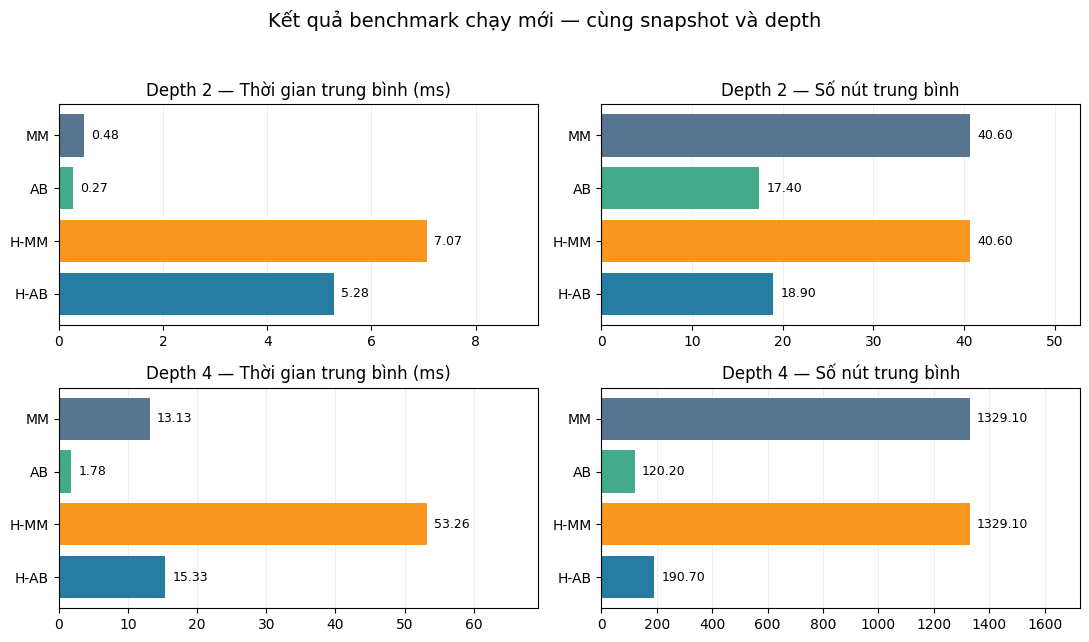

In [6]:
colors = ["#577590", "#43aa8b", "#f8961e", "#277da1"]
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
for row_index, depth in enumerate(DEPTHS):
    part = benchmark_aggregate[benchmark_aggregate["depth"] == depth]
    for col_index, metric, title in (
        (0, "mean_ms", "Thời gian trung bình (ms)"),
        (1, "mean_nodes", "Số nút trung bình"),
    ):
        ax = axes[row_index, col_index]
        values = part[metric].tolist()
        bars = ax.barh([MODE_LABELS[m] for m in part["mode"]], values, color=colors)
        ax.invert_yaxis()
        ax.set_title(f"Depth {depth} — {title}")
        ax.set_xlim(0, max(values) * 1.3)
        ax.xaxis.grid(True, alpha=0.2)
        ax.set_axisbelow(True)
        for bar, value in zip(bars, values):
            ax.text(value + max(values) * 0.02,
                    bar.get_y() + bar.get_height() / 2,
                    f"{value:.2f}", va="center", fontsize=9)
fig.suptitle("Kết quả benchmark chạy mới — cùng snapshot và depth", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.95))
display(fig)
plt.close(fig)

## 5. Đối đầu đổi bên — 60 trận

Gọi trực tiếp `Tournament(depth=3, max_cycles=60, time_limit_ms=None).run(...)`.
Sáu cặp cấu hình × hai cách xếp bên × năm kịch bản = **60 trận**.
Mỗi mode tham gia 30 trận; PV tắt, không deadline và agent reset đầu trận.

Giới hạn 60 cycle chỉ thuộc môi trường chạy thí nghiệm. `unfinished` là chưa
kết thúc, **không phải hòa**; hòa thật là hai bên cùng bị phá. Cache heuristic
có thể dùng lại trong một trận, nên thời gian/nước ở đây không thay phép đo
cùng snapshot. Luật chơi và utility của search được giữ nguyên.

In [7]:
tournament_started = perf_counter()
runner = Tournament(depth=MATCH_DEPTH, max_cycles=MATCH_MAX_CYCLES,
                    time_limit_ms=None)
tournament_rows = runner.run(cases, list(MODES_ORDER))
tournament_df = pd.DataFrame(tournament_rows)
tournament_summary_df = pd.DataFrame(runner.summarize(tournament_rows))
assert len(tournament_rows) == 60
assert (tournament_summary_df["games"] == 30).all()
assert (tournament_summary_df["faults"] == 0).all()
assert not tournament_df["track_pv"].any()
assert (tournament_summary_df["mean_depth"] == MATCH_DEPTH).all()
print(f"PASS: {len(tournament_rows)} trận, không có lỗi agent.")
print(f"Thời gian toàn bộ đối đầu: {perf_counter() - tournament_started:.2f} giây.")

default: P0 minimax / P1 alphabeta: unfinished, experiment_cycle_limit, 60 cycles


default: P0 alphabeta / P1 minimax: unfinished, experiment_cycle_limit, 60 cycles


default: P0 minimax / P1 heuristic_minimax: 1, destroyed, 14 cycles


default: P0 heuristic_minimax / P1 minimax: 0, destroyed, 14 cycles


default: P0 minimax / P1 heuristic_alphabeta: 1, destroyed, 14 cycles


default: P0 heuristic_alphabeta / P1 minimax: 0, destroyed, 14 cycles


... (51 outputs left out)

bullet: P0 heuristic_alphabeta / P1 alphabeta: 0, destroyed, 18 cycles


bullet: P0 heuristic_minimax / P1 heuristic_alphabeta: draw, mutual_destruction, 13 cycles


bullet: P0 heuristic_alphabeta / P1 heuristic_minimax: draw, mutual_destruction, 13 cycles


PASS: 60 trận, không có lỗi agent.
Thời gian toàn bộ đối đầu: 11.83 giây.


In [8]:
ordered_tournament = (tournament_summary_df.set_index("mode")
                      .loc[list(MODES_ORDER)].reset_index())
display(ordered_tournament)
counts = Counter(row["winner"] for row in tournament_rows)
outcomes = pd.DataFrame([
    {"Kết quả": "P0 thắng", "Số trận": counts.get(0, 0)},
    {"Kết quả": "P1 thắng", "Số trận": counts.get(1, 0)},
    {"Kết quả": "Hòa do phá hủy đồng thời", "Số trận": counts.get("draw", 0)},
    {"Kết quả": "Chưa kết thúc (unfinished)", "Số trận": counts.get("unfinished", 0)},
])
assert outcomes["Số trận"].sum() == 60
display(outcomes)
print("Mỗi trận đóng góp hai lượt tham gia; bốn hàng cấu hình không phải 120 trận độc lập.")

,mode,games,wins,losses,draws,unfinished,faults,overtime,mean_move_ms,mean_nodes,mean_evals,mean_order_evals,mean_leaf_evals,mean_depth
0,minimax,30,3,19,0,8,0,0,3.565,240.98,205.69,5.98,199.72,3.0
1,alphabeta,30,3,19,0,8,0,0,1.170,55.90,44.43,5.98,38.45,3.0
2,heuristic_minimax,30,19,3,8,0,0,0,13.066,231.63,198.29,5.99,192.31,3.0
3,heuristic_alphabeta,30,19,3,8,0,0,0,5.643,59.21,48.17,5.99,42.19,3.0


,Kết quả,Số trận
0,P0 thắng,16
1,P1 thắng,28
2,Hòa do phá hủy đồng thời,8
3,Chưa kết thúc (unfinished),8


Mỗi trận đóng góp hai lượt tham gia; bốn hàng cấu hình không phải 120 trận độc lập.


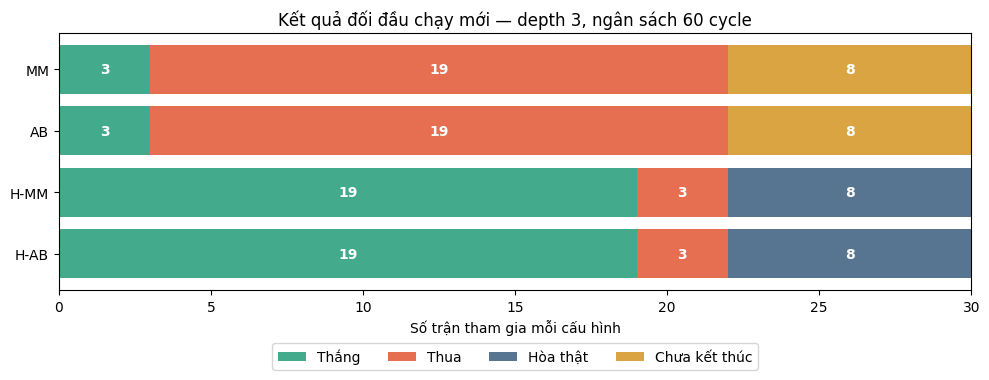

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
left = [0] * len(ordered_tournament)
for column, label, color in (
    ("wins", "Thắng", "#43aa8b"),
    ("losses", "Thua", "#e76f51"),
    ("draws", "Hòa thật", "#577590"),
    ("unfinished", "Chưa kết thúc", "#d9a441"),
):
    values = ordered_tournament[column].astype(int).tolist()
    bars = ax.barh([MODE_LABELS[m] for m in ordered_tournament["mode"]],
                   values, left=left, label=label, color=color)
    for bar, start, value in zip(bars, left, values):
        if value:
            ax.text(start + value / 2, bar.get_y() + bar.get_height() / 2,
                    str(value), ha="center", va="center", color="white", fontweight="bold")
    left = [a + b for a, b in zip(left, values)]
ax.invert_yaxis()
ax.set_xlim(0, 30)
ax.set_xlabel("Số trận tham gia mỗi cấu hình")
ax.set_title("Kết quả đối đầu chạy mới — depth 3, ngân sách 60 cycle")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18))
fig.tight_layout()
display(fig)
plt.close(fig)

## 6. Đối chiếu bộ CSV tham khảo đang có trong báo cáo

Các bảng sau **đọc dữ liệu đã lưu**, khác với số liệu vừa chạy ở mục 4–5.
Thời gian có thể khác do máy, tải hệ thống và lần chạy; không sửa số liệu cũ
để làm khớp thời gian mới. Nếu cập nhật báo cáo bằng kết quả mới, dùng nhất
quán một bộ kết quả và ghi lại môi trường đo.

In [10]:
reference_search = pd.read_csv(ROOT / "experiments/search_fixed_depth.csv",
                               encoding="utf-8-sig")
reference_tournament = pd.read_csv(ROOT / "experiments/tournament_fixed_depth_summary.csv",
                                   encoding="utf-8-sig")
reference_environment = json.loads((ROOT / "experiments/environment.json").read_text())
reference_aggregate = (reference_search.groupby(["depth", "mode"], as_index=False)
    .agg(samples=("time_ms", "size"), mean_ms=("time_ms", "mean"),
         mean_nodes=("nodes", "mean"), mean_cutoffs=("cutoffs", "mean")))
reference_aggregate["mode"] = pd.Categorical(
    reference_aggregate["mode"], categories=list(MODES_ORDER), ordered=True
)
print("Bộ tham khảo:", reference_environment.get("profile"))
print("Môi trường tham khảo:", reference_environment.get("system"),
      reference_environment.get("machine"), reference_environment.get("python"))
display(reference_aggregate.sort_values(["depth", "mode"]).reset_index(drop=True).round(6))
display(reference_tournament.set_index("mode").loc[list(MODES_ORDER)].reset_index())

Bộ tham khảo: assignment_four_modes_v1
Môi trường tham khảo: Linux x86_64 3.12.14


,depth,mode,samples,mean_ms,mean_nodes,mean_cutoffs
0,2,minimax,30,0.357090,40.6,0.0
1,2,alphabeta,30,0.241252,17.4,4.8
2,2,heuristic_minimax,30,4.826341,40.6,0.0
3,2,heuristic_alphabeta,30,3.961600,18.9,4.5
4,4,minimax,30,9.370221,1329.1,0.0
5,4,alphabeta,30,1.376102,120.2,41.6
6,4,heuristic_minimax,30,40.807087,1329.1,0.0
7,4,heuristic_alphabeta,30,11.578550,190.7,48.2


,mode,games,wins,losses,draws,unfinished,faults,overtime,mean_move_ms,mean_nodes,mean_evals,mean_order_evals,mean_leaf_evals,mean_depth
0,minimax,30,3,19,0,8,0,0,3.383,240.98,205.69,5.98,199.72,3.0
1,alphabeta,30,3,19,0,8,0,0,1.073,55.90,44.43,5.98,38.45,3.0
2,heuristic_minimax,30,19,3,8,0,0,0,12.666,231.63,198.29,5.99,192.31,3.0
3,heuristic_alphabeta,30,19,3,8,0,0,0,4.940,59.21,48.17,5.99,42.19,3.0


## 7. Dữ liệu thô của lần chạy notebook

Mở hai khối bên dưới để xem đầy đủ từng lượt đo/trận. Các bảng được nhúng
trong output `.ipynb`, không cần tệp CSV phát sinh để đọc lại kết quả.

In [11]:
display(HTML("<details><summary>Benchmark: toàn bộ 240 lượt đo mới</summary>"
             + benchmark_df.to_html(index=False) + "</details>"))
display(HTML("<details><summary>Đối đầu: toàn bộ 60 trận mới</summary>"
             + tournament_df.to_html(index=False) + "</details>"))
print(f"Đã lưu trong output: {len(benchmark_df)} lượt benchmark và {len(tournament_df)} trận.")

scenario,player,depth,repeat,mode,evaluator,action,score,time_ms,nodes,leaves,cutoffs,pruned_actions,order_evals,leaf_evals,track_pv,total_evals,depth_reached,nodes_per_second
default,0,2,1,heuristic_minimax,heuristic,MOVE_LEFT,0.0,21.885806,43,36,0,0,6,36,False,42,2,1964.7
default,0,2,1,alphabeta,terminal_only,FIRE,0.0,0.255832,18,11,5,25,6,11,False,17,2,70358.7
default,0,2,1,heuristic_alphabeta,heuristic,MOVE_LEFT,0.0,11.269940,18,11,5,25,6,11,False,17,2,1597.2
default,0,2,1,minimax,terminal_only,FIRE,0.0,0.413303,43,36,0,0,6,36,False,42,2,104039.9
default,0,2,2,heuristic_alphabeta,heuristic,MOVE_LEFT,0.0,12.415102,18,11,5,25,6,11,False,17,2,1449.8
default,0,2,2,heuristic_minimax,heuristic,MOVE_LEFT,0.0,21.892996,43,36,0,0,6,36,False,42,2,1964.1
default,0,2,2,minimax,terminal_only,FIRE,0.0,0.516341,43,36,0,0,6,36,False,42,2,83278.3
default,0,2,2,alphabeta,terminal_only,FIRE,0.0,0.253874,18,11,5,25,6,11,False,17,2,70901.3
default,0,2,3,alphabeta,terminal_only,FIRE,0.0,0.223216,18,11,5,25,6,11,False,17,2,80639.4
default,0,2,3,heuristic_alphabeta,heuristic,MOVE_LEFT,0.0,15.780845,18,11,5,25,6,11,False,17,2,1140.6


scenario,mode0,mode1,evaluator0,evaluator1,depth,time_limit_ms,max_cycles,track_pv,winner,status,reason,cycles,tank_hp0,tank_hp1,base_hp0,base_hp1,faults0,overtime0,time_ms0,nodes0,evals0,order_evals0,leaf_evals0,moves0,depth_sum0,faults1,overtime1,time_ms1,nodes1,evals1,order_evals1,leaf_evals1,moves1,depth_sum1
default,minimax,alphabeta,terminal_only,terminal_only,3,None,60,False,unfinished,stopped,experiment_cycle_limit,60,6,6,9,9,0,0,159.533690,14802,12582,360,12222,60,180,0,0,92.554812,3417,2697,360,2337,60,180
default,alphabeta,minimax,terminal_only,terminal_only,3,None,60,False,unfinished,stopped,experiment_cycle_limit,60,6,6,9,9,0,0,47.484996,3417,2697,360,2337,60,180,0,0,258.207663,14802,12582,360,12222,60,180
default,minimax,heuristic_minimax,terminal_only,heuristic,3,None,60,False,1,finished,destroyed,14,6,6,0,9,0,0,34.526126,3236,2754,84,2670,14,42,0,0,292.975883,3218,2742,84,2658,14,42
default,heuristic_minimax,minimax,heuristic,terminal_only,3,None,60,False,0,finished,destroyed,14,6,6,9,0,0,0,240.387644,3254,2772,84,2688,14,42,0,0,80.339698,3200,2724,84,2640,14,42
default,minimax,heuristic_alphabeta,terminal_only,heuristic,3,None,60,False,1,finished,destroyed,14,6,6,0,9,0,0,39.445060,3236,2754,84,2670,14,42,0,0,142.316982,826,675,84,591,14,42
default,heuristic_alphabeta,minimax,heuristic,terminal_only,3,None,60,False,0,finished,destroyed,14,6,6,9,0,0,0,102.750492,895,722,84,638,14,42,0,0,73.803450,3200,2724,84,2640,14,42
default,alphabeta,heuristic_minimax,terminal_only,heuristic,3,None,60,False,1,finished,destroyed,14,6,6,0,9,0,0,13.679148,756,599,84,515,14,42,0,0,272.658048,3218,2742,84,2658,14,42
default,heuristic_minimax,alphabeta,heuristic,terminal_only,3,None,60,False,0,finished,destroyed,14,6,6,9,0,0,0,274.003198,3254,2772,84,2688,14,42,0,0,28.289936,745,594,84,510,14,42
default,alphabeta,heuristic_alphabeta,terminal_only,heuristic,3,None,60,False,1,finished,destroyed,14,6,6,0,9,0,0,10.764597,756,599,84,515,14,42,0,0,237.117122,826,675,84,591,14,42
default,heuristic_alphabeta,alphabeta,heuristic,terminal_only,3,None,60,False,0,finished,destroyed,14,6,6,9,0,0,0,108.975556,895,722,84,638,14,42,0,0,24.866007,745,594,84,510,14,42


Đã lưu trong output: 240 lượt benchmark và 60 trận.


## 8. Kiểm tra tính toàn vẹn và nhận xét

- Minimax và Alpha-Beta cùng evaluator/depth phải khớp giá trị khi hoàn tất.
  Đồng điểm có thể cho hành động khác nhau; cùng giá trị không buộc mọi trận giống nhau.
- Heuristic hỗ trợ phân biệt trạng thái chưa terminal nhưng có chi phí tính toán.
  Đánh giá hiệu quả tìm kiếm và kết quả chơi là hai phép so sánh khác nhau.
- Nhiều lá 0 có thể khiến bản thuần lặp FIRE. Điều này không chứng minh Minimax
  không chọn được di chuyển; bộ kiểm thử có tình huống né khi nhìn thấy thua.
- Kết luận chỉ áp dụng cho map, độ sâu và ngân sách đã đo, không chứng minh
  tối ưu cả ván hoặc heuristic luôn thắng. Chưa có số đo trên máy macOS Intel i5 của đề.
- Notebook giữ nguyên mã nguồn và CSV tham khảo, xác nhận bằng SHA-256 ở cell cuối.

In [12]:
source_hashes_after = {str(p.relative_to(ROOT)): sha256(p) for p in SOURCE_FILES}
reference_hashes_after = {str(p.relative_to(ROOT)): sha256(p) for p in REFERENCE_FILES}
assert source_hashes_after == source_hashes_before, "Có thay đổi mã nguồn trong lúc chạy."
assert reference_hashes_after == reference_hashes_before, "Có thay đổi CSV/JSON tham khảo."
assert test_run.returncode == 0 and pairs_checked == 120
assert len(benchmark_rows) == 240 and len(tournament_rows) == 60
assert tournament_summary_df["faults"].sum() == 0

display(pd.DataFrame([
    {"File nguồn": name, "SHA-256": digest}
    for name, digest in source_hashes_after.items()
]))
print("PASS: Mã nguồn và dữ liệu tham khảo không đổi sau khi chạy notebook.")
print("PASS: Kiểm thử đạt; 240 lượt benchmark; 120 cặp khớp điểm; 60 trận không lỗi agent.")
print("Notebook đã hoàn tất. Khi chạy lại, hãy Save để giữ output của tất cả các cell.")

,File nguồn,SHA-256
0,ai_battle.py,9b23d86a11c672dabc528cc64142c0da02ad4c8f1fba2a...
1,arena.py,b92617743f22ef6adcc97b3a554aeac095ba3d6f4af767...
2,presentation.py,80d407d18da1094da1f307aceed80e4b204360d9d4a34f...
3,tanks.py,21788c41a27754b2404416daa1b04941c761181ad0357b...
4,task2/agent.py,d2578bb09f568fd0e0c963e8d4fa3525c19a7010b458f9...
5,task2/benchmark.py,dd83697e39ed4cbd00c7bc27ddda1da1a3b956b799f635...
6,task2/external_greedy.py,f291da1891501bfc25a7df726fe9592e07fcd9872d3743...
7,task2/game.py,017799194b5f8b5f35e2d9d7872ca41c570839f47fe857...
8,task2/heuristics.py,5200d297c63b1e35b9ab6f871db584979d094e862acd99...
9,task2/original_maps.py,a99eff56f44262aab0aaec09ff28e8564c88828a51b2d0...


PASS: Mã nguồn và dữ liệu tham khảo không đổi sau khi chạy notebook.
PASS: Kiểm thử đạt; 240 lượt benchmark; 120 cặp khớp điểm; 60 trận không lỗi agent.
Notebook đã hoàn tất. Khi chạy lại, hãy Save để giữ output của tất cả các cell.
